# Radon Transform and CT Projections

## Objective

Simulate CT projections from the Shepp-Logan phantom using the Radon transform.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from skimage.transform import radon

from medimaging.simulation.phantom import create_shepp_logan

## 1. Input Image

We use the Shepp-Logan phantom as a known reference image.

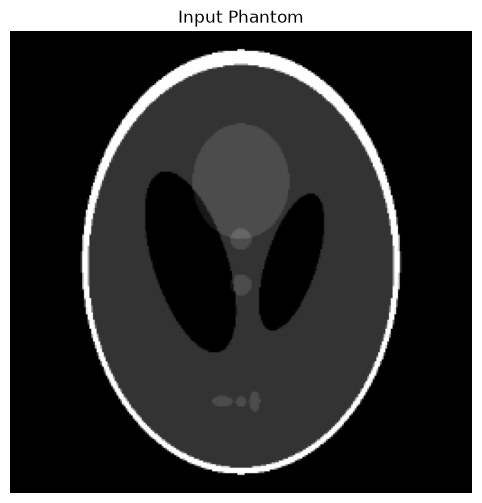

In [2]:
phantom = create_shepp_logan(256)

plt.figure(figsize=(6, 6))
plt.imshow(phantom, cmap="gray")
plt.title("Input Phantom")
plt.axis("off")
plt.show()

## 2. Projection Angles

CT acquisition measures projections from multiple viewing angles.

In [3]:
theta = np.linspace(0.0, 180.0, 180, endpoint=False)

print("Number of projection angles:", len(theta))

Number of projection angles: 180


## 3. Radon Transform

The Radon transform computes line integrals through the image at different angles.
These projections form the basis of CT reconstruction.

In [4]:
sinogram = radon(phantom, theta=theta, circle=True)

print("Sinogram shape:", sinogram.shape)

Sinogram shape: (256, 180)


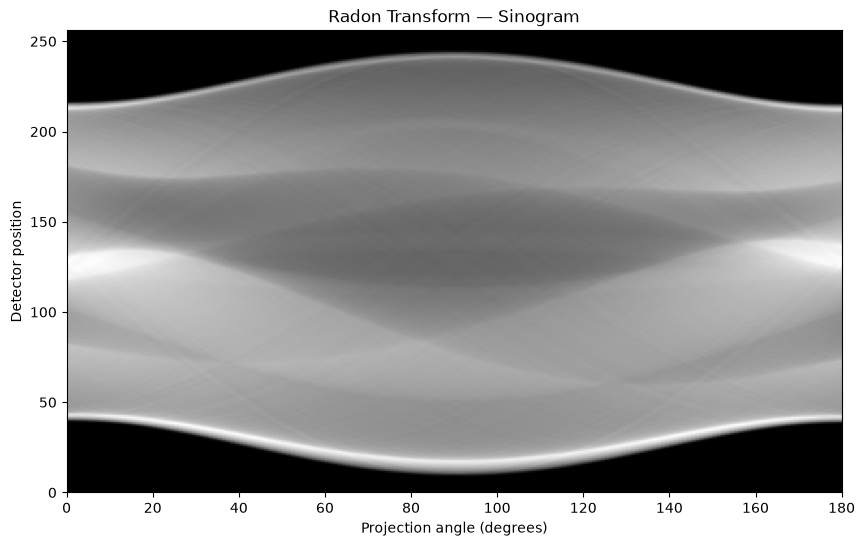

In [5]:
plt.figure(figsize=(10, 6))

plt.imshow(
    sinogram,
    cmap="gray",
    extent=(0, 180, 0, sinogram.shape[0]),
    aspect="auto",
)

plt.title("Radon Transform — Sinogram")
plt.xlabel("Projection angle (degrees)")
plt.ylabel("Detector position")

plt.show()

## 4. Projection Profiles

Individual columns of the sinogram represent projections acquired at specific angles.

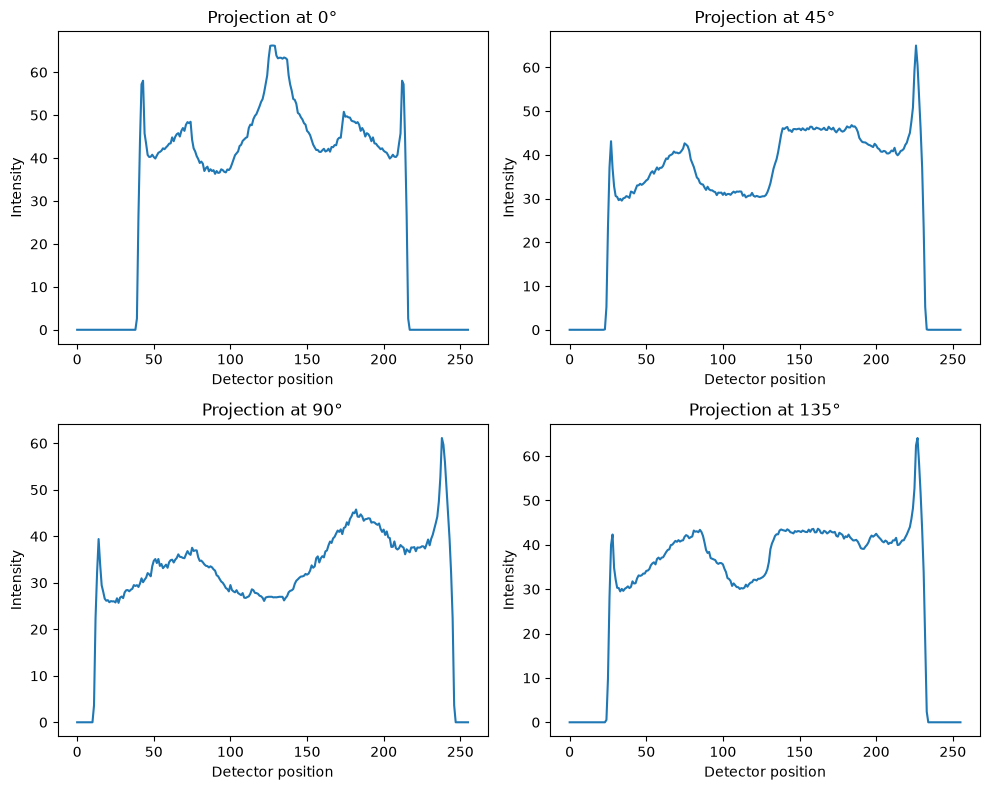

In [6]:
angles_to_show = [0, 45, 90, 135]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, angle in zip(axes.ravel(), angles_to_show, strict=True):
    index = int(angle)
    ax.plot(sinogram[:, index])
    ax.set_title(f"Projection at {angle}°")
    ax.set_xlabel("Detector position")
    ax.set_ylabel("Intensity")

plt.tight_layout()
plt.show()

## 5. Conclusions

The Radon transform converts the phantom into a set of projections acquired
at different angles.

These projections form the sinogram, which is the input representation used
by reconstruction algorithms such as filtered back projection.